# 06 · Routing and switch adaptation

Diagnostic questions: are experts used, do routes correspond to regimes, and how do errors change after switches?

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Load diagnostic results

Permutation matching is fitted on validation routes and evaluated on test routes.

In [2]:
from twilight_moe.experiment import load_metrics, load_diagnostics
from twilight_moe.models import MODEL_NAMES
seed = cfg['seeds'][0]
results = load_metrics(cfg)
diagnostics = {name: load_diagnostics(cfg, name, seed) for name in MODEL_NAMES}
display(results.loc[results.model.isin(['moe', 'random', 'oracle']),
                    ['model', 'seed', 'routing_agreement']].round(4))

,model,seed,routing_agreement
2,moe,7,0.4582
3,random,7,0.3552
4,oracle,7,1.0000
7,moe,17,0.6008
8,random,17,0.3447
9,oracle,17,1.0000
12,moe,27,0.4828
13,random,27,0.3643
14,oracle,27,1.0000


## Plot expert utilization

Shares count all selected top-k slots. They sum to one, even when k is two.

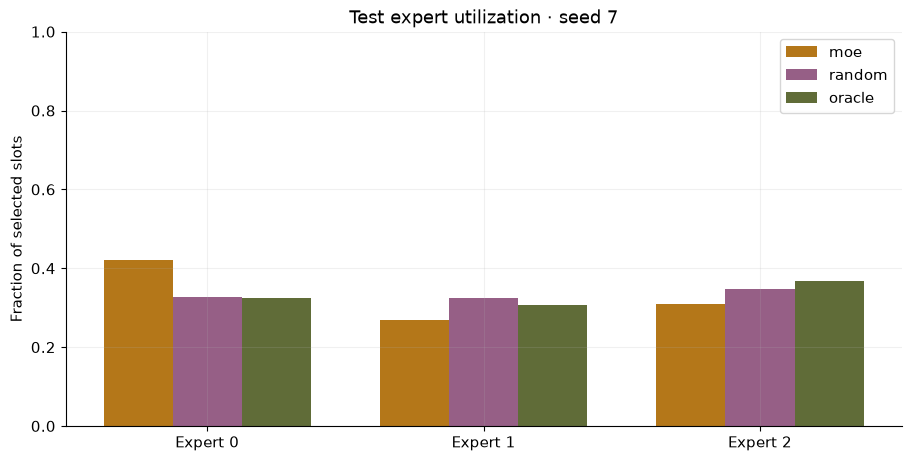

In [3]:
fig, ax = plt.subplots()
for j, name in enumerate(['moe', 'random', 'oracle']):
    ax.bar(np.arange(3)+(j-1)*.25, diagnostics[name]['utilization'], width=.25,
           color=COLORS[name], label=name)
ax.set(xticks=np.arange(3), xticklabels=['Expert 0', 'Expert 1', 'Expert 2'],
       ylabel='Fraction of selected slots', title=f'Test expert utilization · seed {seed}', ylim=(0, 1))
ax.legend()
save_figure(fig, cfg, 'expert_utilization')
plt.show()

## Plot regime–expert correspondence

Raw test counts use the top-weight selected expert. IDs are arbitrary.

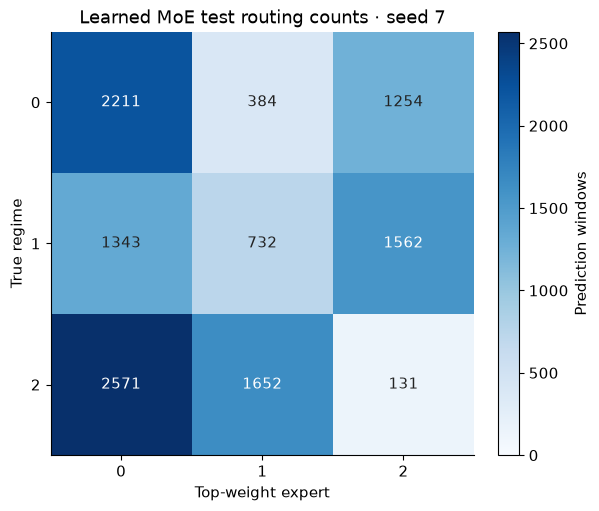

In [4]:
fig, ax = plt.subplots(figsize=(6, 5))
counts = diagnostics['moe']['confusion']
im = ax.imshow(counts, cmap='Blues', vmin=0)
for row in range(3):
    for col in range(3):
        ax.text(col, row, str(counts[row, col]), ha='center', va='center',
                color='white' if counts[row, col] > counts.max()*.55 else '#222222')
ax.set(xticks=range(3), yticks=range(3), xlabel='Top-weight expert', ylabel='True regime',
       title=f'Learned MoE test routing counts · seed {seed}')
ax.grid(False)
fig.colorbar(im, ax=ax, label='Prediction windows')
save_figure(fig, cfg, 'routing_confusion')
plt.show()

## Plot switch-aligned error and support

At lag zero, a switch may not yet be inferable from the observed history. Episodes stop at the next switch; support decreases with lag.

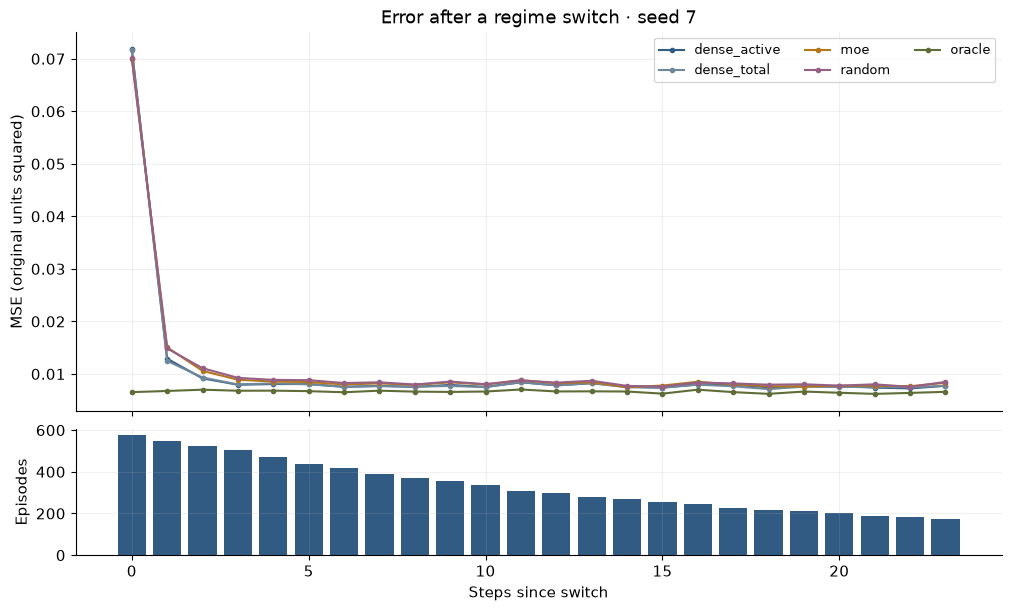

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, height_ratios=[3, 1])
for name in MODEL_NAMES:
    axes[0].plot(diagnostics[name]['adaptation_mse'], color=COLORS[name], label=name, marker='.')
axes[0].set(title=f'Error after a regime switch · seed {seed}', ylabel='MSE (original units squared)')
axes[0].legend(ncol=3, fontsize=9)
axes[1].bar(np.arange(cfg['evaluation']['adaptation_window']), diagnostics['moe']['adaptation_counts'], color='#315b83')
axes[1].set(xlabel='Steps since switch', ylabel='Episodes')
save_figure(fig, cfg, 'switch_adaptation')
plt.show()

## Inspect recovery and censoring

Recovery means three consecutive errors below a model-specific validation threshold (see research plan). Delays are conditional on recovery and should be read with recovered fractions.

In [6]:
display(results[['model', 'seed', 'switch_episodes', 'recovered_episodes', 'recovered_fraction',
                 'recovery_delay_steps', 'recovery_threshold']].round(5))

,model,seed,switch_episodes,recovered_episodes,recovered_fraction,recovery_delay_steps,recovery_threshold
0,dense_active,7,578,443,0.76644,2.62754,0.01173
1,dense_total,7,578,444,0.76817,2.65991,0.01169
2,moe,7,578,448,0.77509,2.86161,0.01223
3,random,7,578,440,0.76125,2.80909,0.01260
4,oracle,7,578,478,0.82699,1.39331,0.01000
5,dense_active,17,556,420,0.75540,2.56190,0.01179
6,dense_total,17,556,418,0.75180,2.63876,0.01159
7,moe,17,556,414,0.74460,2.86232,0.01195
8,random,17,556,412,0.74101,3.03155,0.01239
9,oracle,17,556,451,0.81115,1.49889,0.00998


## Interpretation

Routing agreement is a descriptive diagnostic. Good prediction does not require one expert per regime, and correspondence alone is not evidence of a causal mechanism.